# 26. Seismic waves from the explosion, ahead of the airwave

At KSC we have had no clear recording of a seismic wavetrain from a rocket before, for two reasons. The
stations are usually close to the source, so seismic and acoustic arrivals overlap. And launches are
emergent sources. An impulsive source 12–21 km away separates the two: seismic energy arrives tens of
seconds before the airwave.

This notebook:

* shows the three-component ground velocity at the working Trilliums (B20, B14, B29, B05) from the origin
  to just after the airwave;
* picks the **first seismic arrival** (STA/LTA, refined on the envelope) and the **peak of the seismic
  wavetrain**, and converts them to apparent velocities with the origin from `24_origin_time.ipynb`;
* estimates **group velocity against frequency** from narrow-band envelopes;
* compares the **spectra** of the seismic wavetrain, the pre-event noise and the air-coupled ground motion,
  and their **amplitudes**.

Output (`cfg.OUT_DIR / "26_seismic_arrivals"`): `seismic_record_section.png`, `seismic_picks.csv`,
`group_velocity.csv`, `group_velocity.png`, `seismic_spectra.png`, `seismic_amplitudes.csv`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from obspy.signal.trigger import classic_sta_lta
from obspy.signal.filter import envelope
from scipy.signal import welch

import newglenn_config as cfg

warnings.filterwarnings('ignore', message='ObsPy can not map unit')
ORIGIN = cfg.ORIGIN
OUT = cfg.output_dir('26_seismic_arrivals')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
stations = cfg.station_table()
air = cfg.airwave_speeds()
STAS = ['B20', 'B14', 'B29', 'B05']                     # working Trilliums, by distance
raw = cfg.event_stream_raw(starttime=ORIGIN - 300, endtime=ORIGIN + 300)
st = cfg.instrument_correct(raw).select(channel='?H?')
FULL = 2 ** 23
usable = {}
for tr in raw.select(channel='?H?'):
    s = tr.slice(ORIGIN - 10, ORIGIN + 150).data.astype(float)
    n = tr.slice(ORIGIN - 250, ORIGIN - 20).data.astype(float)
    usable[tr.id] = tr.stats.station in STAS and n.std() > 5 and np.abs(s).max() < 0.8 * FULL
st = st.__class__([tr for tr in st if usable.get(tr.id)])
print('usable:', sorted(tr.id for tr in st))
print(air.loc[STAS, ['distance_m', 'azimuth_deg', 'travel_time_s']].round(2))

/Users/glennthompson/Developer/KSCRocketSeismoHydrology/.claude/worktrees/newglenn-paper-7faf3d/ksclib/src/ksclib/centaur.py:136: UserWarning: B14: no Centaur response before 2026-05-29T01:00:02.370000Z; using 1R.B14_20260614T135243Z.xml (16.5 days later)
  warnings.warn(str(m.message))


usable: ['1R.B05.00.CH1', '1R.B05.00.CHZ', '1R.B14.00.CH1', '1R.B14.00.CH2', '1R.B14.00.CHZ', '1R.B20.00.HH1', '1R.B20.00.HH2', '1R.B20.00.HHZ', '1R.B29.00.CH1', '1R.B29.00.CH2', '1R.B29.00.CHZ']
         distance_m  azimuth_deg  travel_time_s
station                                        
B20        11793.38       345.58          33.96
B14        19311.80       338.11          55.64
B29        21002.68       321.14          60.57
B05        21303.72       331.85          61.41


## Three-component record section (2–12 Hz)

Each trace is scaled to the largest *seismic* amplitude before the airwave, so the airwave-coupled motion
(which is larger) runs off the scale. The horizontal components are H1/H2 as installed (not rotated).

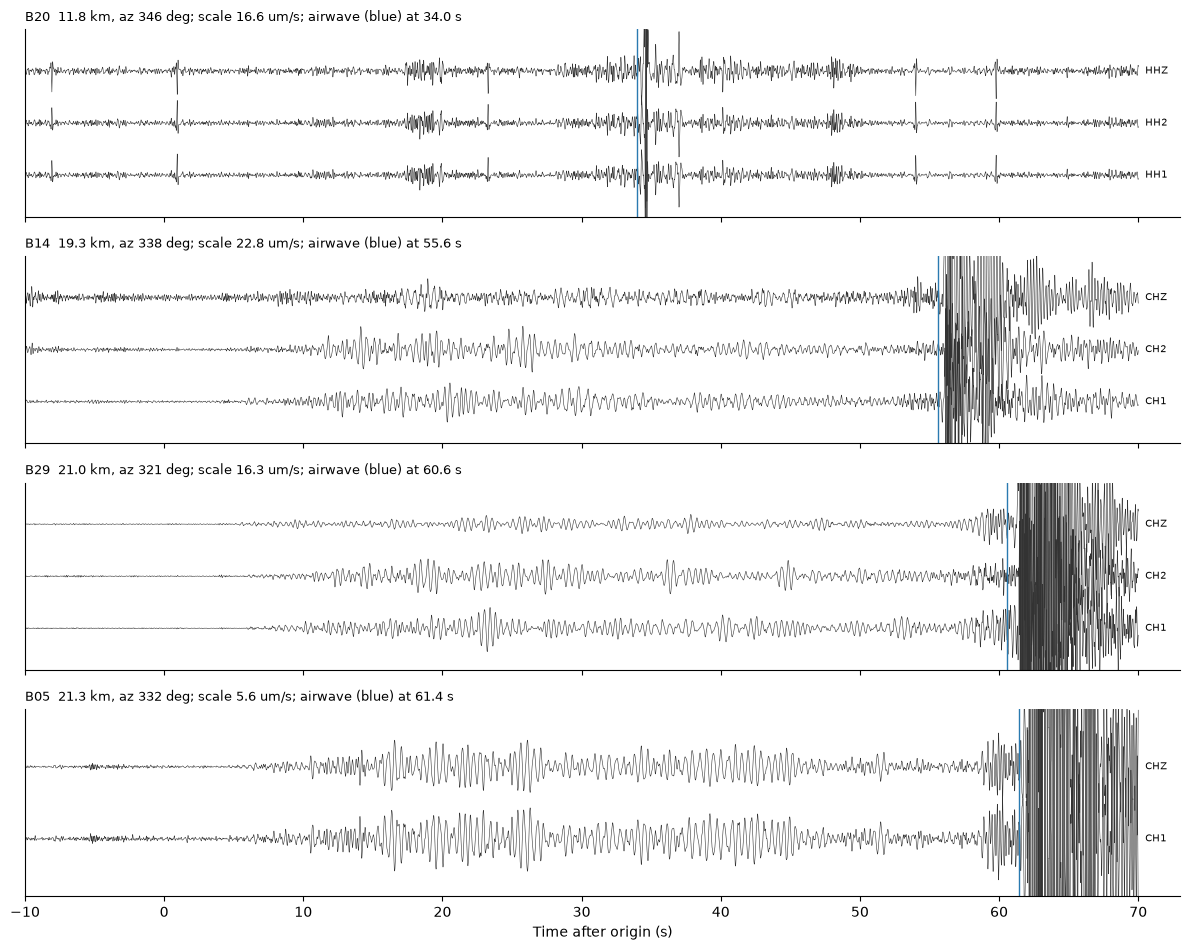

In [2]:
BAND = dict(freqmin=2.0, freqmax=12.0, corners=4, zerophase=True)
T0, T1 = -10, 70
fig, axs = plt.subplots(len(STAS), 1, figsize=(12, 2.4 * len(STAS)), sharex=True)
for ax, sta in zip(axs, STAS):
    ta = air.travel_time_s[sta]
    trs = st.select(station=sta)
    seis = [tr.copy().filter('bandpass', **BAND).slice(ORIGIN + T0, ORIGIN + T1) for tr in trs]
    pre = max(np.abs(t.slice(ORIGIN + 0, ORIGIN + ta - 2).data).max() for t in seis)
    for j, t in enumerate(sorted(seis, key=lambda t: t.stats.channel[::-1])):
        ax.plot(t.times() + T0, j + 0.45 * t.data / pre, lw=0.4, color='#333333')
        ax.text(T1 + 0.5, j, t.stats.channel, fontsize=7, va='center')
    ax.axvline(ta, color='#2a7ab0', lw=1)
    ax.set_ylim(-0.8, len(seis) - 0.2); ax.set_yticks([])
    ax.set_title(f'{sta}  {stations.distance_km[sta]:.1f} km, az {air.azimuth_deg[sta]:.0f} deg; '
                 f'scale {pre * 1e6:.1f} um/s; airwave (blue) at {ta:.1f} s', loc='left', fontsize=9)
axs[-1].set(xlim=(T0, T1 + 3), xlabel='Time after origin (s)')
fig.tight_layout()
fig.savefig(OUT / 'seismic_record_section.png', dpi=150, bbox_inches='tight')

## First arrival and wavetrain peak

The seismic arrival is emergent, so threshold pickers depend on the threshold. Instead:

* **First arrival**: AIC picker (minimum of the Akaike criterion between a noise and a signal segment) on
  the vector amplitude of all usable components, from 20 s before to 20 s after the origin, in two bands
  (2–12 Hz and 1–5 Hz). The spread between the two is a measure of the pick uncertainty. At B20 the noise
  is about ten times higher than at B29 and B05 (local machinery and repeating transients), and the AIC
  finds the burst at about 17 s instead. That burst is listed separately, and no first arrival is given
  for B20.
* **Wavetrain peak**: time of the maximum of the 2 s-smoothed vector envelope (2–12 Hz) before the airwave.

Apparent velocities are distance / time after the origin. The origin uncertainty (about ±1 s) maps to
about ±0.4 km/s at 3 km/s and 20 km.

In [3]:
def smooth(x, n):
    return np.convolve(x, np.ones(n) / n, mode='same')

def aic_pick(x):
    n = len(x)
    k = np.arange(1, n - 1)
    c = np.cumsum(x ** 2)
    v1, v2 = c[k - 1] / k, (c[-1] - c[k - 1]) / (n - k)
    return k[np.argmin(k * np.log(v1 + 1e-30) + (n - k - 1) * np.log(v2 + 1e-30))]

def vector(sta, t0, t1, **band):
    tot = None
    for tr in st.select(station=sta):
        x = tr.copy().filter('bandpass', **band).slice(ORIGIN + t0, ORIGIN + t1).data ** 2
        tot = x if tot is None else tot[:len(x)] + x[:len(tot)]
    return np.sqrt(tot), st.select(station=sta)[0].stats.sampling_rate

rows = []
for sta in STAS:
    ta = air.travel_time_s[sta]
    r = dict(station=sta, distance_m=air.distance_m[sta], airwave_s=ta)
    for lab, band in (('2_12', BAND), ('1_5', dict(freqmin=1.0, freqmax=5.0, corners=4, zerophase=True))):
        v, fs = vector(sta, -20, 20, **band)
        r[f'aic_{lab}_s'] = aic_pick(v) / fs - 20
    v, fs = vector(sta, -120, ta - 3, **BAND)
    t = np.arange(len(v)) / fs - 120
    env = smooth(v, int(2 * fs))
    m = t > 0
    r['wavetrain_peak_s'] = t[np.flatnonzero(m)[np.argmax(env[m])]]
    z = st.select(station=sta, channel='?HZ')[0].copy().filter('bandpass', **BAND)
    r['noise_rms_z_um_s'] = np.sqrt(np.mean(z.slice(ORIGIN - 100, ORIGIN - 5).data ** 2)) * 1e6
    r['seismic_peak_z_um_s'] = np.abs(z.slice(ORIGIN, ORIGIN + ta - 3).data).max() * 1e6
    rows.append(r)
picks = pd.DataFrame(rows).set_index('station')
picks['first_arrival_s'] = picks[['aic_2_12_s', 'aic_1_5_s']].mean(axis=1)
picks['first_arrival_spread_s'] = (picks.aic_2_12_s - picks.aic_1_5_s).abs()
b20_burst = picks.loc['B20', 'first_arrival_s']
picks.loc['B20', ['first_arrival_s', 'first_arrival_spread_s']] = np.nan    # buried in B20's noise
picks['v_first_km_s'] = picks.distance_m / 1000 / picks.first_arrival_s
picks['v_first_range_km_s'] = [f'{d / 1000 / max(a, b):.2f}-{d / 1000 / min(a, b):.2f}' if sta != 'B20' else ''
                               for sta, d, a, b in zip(picks.index, picks.distance_m, picks.aic_2_12_s, picks.aic_1_5_s)]
picks['v_peak_km_s'] = picks.distance_m / 1000 / picks.wavetrain_peak_s
picks['snr_z'] = picks.seismic_peak_z_um_s / picks.noise_rms_z_um_s
picks['lead_over_airwave_s'] = picks.airwave_s - picks.first_arrival_s
picks.to_csv(OUT / 'seismic_picks.csv')
display(picks.round(2))
print(f'B20: AIC finds the burst at {b20_burst:.1f} s ({air.distance_m["B20"] / 1000 / b20_burst:.2f} km/s), '
      'not a first arrival.')

,distance_m,airwave_s,aic_2_12_s,aic_1_5_s,wavetrain_peak_s,noise_rms_z_um_s,seismic_peak_z_um_s,first_arrival_s,first_arrival_spread_s,v_first_km_s,v_first_range_km_s,v_peak_km_s,snr_z,lead_over_airwave_s
station,,,,,,,,,,,,,,
B20,11793.38,33.96,17.33,17.29,19.08,1.80,16.60,NaN,NaN,NaN,,0.62,9.25,NaN
B14,19311.80,55.64,8.16,9.15,19.81,2.23,18.37,8.65,0.99,2.23,2.11-2.37,0.97,8.23,46.99
B29,21002.68,60.57,5.55,6.38,23.23,0.15,6.74,5.96,0.83,3.52,3.29-3.79,0.90,45.93,54.61
B05,21303.72,61.41,7.84,6.52,26.13,0.10,4.63,7.18,1.32,2.97,2.72-3.27,0.82,45.19,54.23


B20: AIC finds the burst at 17.3 s (0.68 km/s), not a first arrival.


## Group velocity against frequency

Narrow-band (one-octave) vector envelopes, 2 s-smoothed; the group arrival in each band is the envelope
maximum between the first arrival and 3 s before the airwave. Shown for the three stations at 19–21 km,
where the seismic and acoustic arrivals are well separated.

u_km_s                snr                
station    B05   B14   B29    B05     B14     B29
band_hz                                          
1-2       0.79  0.65  0.57  81.45  529.44  256.48
16-32     1.70  2.14  2.38   9.78    2.09    7.84
2-4       0.82  0.98  0.92  75.63   20.31  252.12
4-8       1.58  1.00  1.23  27.02    2.81   27.52
8-16      0.49  1.22  0.37   6.13    2.29    6.58

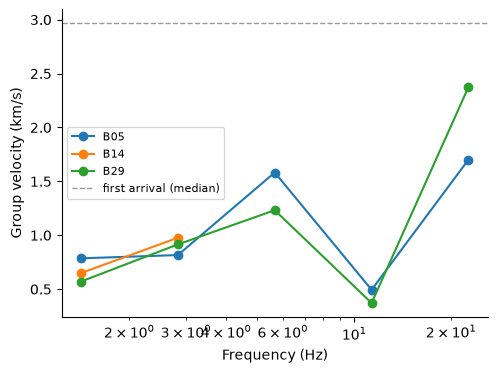

In [4]:
BANDS = [(1, 2), (2, 4), (4, 8), (8, 16), (16, 32)]
rows = []
for sta in ['B14', 'B29', 'B05']:
    ta, t_on = air.travel_time_s[sta], picks.first_arrival_s[sta]
    for lo, hi in BANDS:
        vec = None
        for tr in st.select(station=sta):
            x = tr.copy().filter('bandpass', freqmin=lo, freqmax=hi, corners=4, zerophase=True)
            s = x.slice(ORIGIN, ORIGIN + ta - 3)
            e = envelope(s.data) ** 2
            vec = e if vec is None else vec[:len(e)] + e[:len(vec)]
        fs = s.stats.sampling_rate
        venv = smooth(np.sqrt(vec), int(2 * fs))
        t = np.arange(len(venv)) / fs
        m = t > (t_on if np.isfinite(t_on) else 0)
        i = np.flatnonzero(m)[np.argmax(venv[m])]
        noise = np.sqrt(np.mean(st.select(station=sta, channel='?HZ')[0].copy()
                                .filter('bandpass', freqmin=lo, freqmax=hi).slice(ORIGIN - 100, ORIGIN - 5).data ** 2))
        rows.append(dict(station=sta, band_hz=f'{lo}-{hi}', f_center_hz=np.sqrt(lo * hi), t_group_s=t[i],
                         u_km_s=air.distance_m[sta] / 1000 / t[i], snr=venv[i] / noise))
gv = pd.DataFrame(rows)
gv.to_csv(OUT / 'group_velocity.csv', index=False)
display(gv.pivot(index='band_hz', columns='station', values=['u_km_s', 'snr']).round(2))
fig, ax = plt.subplots(figsize=(5.5, 4))
for sta, g in gv.groupby('station'):
    ok = g.snr > 3
    ax.semilogx(g.f_center_hz[ok], g.u_km_s[ok], 'o-', label=sta)
ax.axhline(np.median(picks.loc[['B14', 'B29', 'B05'], 'v_first_km_s']), color='#999999', ls='--', lw=1,
           label='first arrival (median)')
ax.set(xlabel='Frequency (Hz)', ylabel='Group velocity (km/s)')
ax.legend(fontsize=8)
fig.savefig(OUT / 'group_velocity.png', dpi=150, bbox_inches='tight')

## Spectra and amplitudes

Vertical velocity PSDs (Welch, 2.56 s segments at 500 samples/s; 100 at B20) in three windows: pre-event
noise (−100 to −5 s), the seismic wavetrain (first arrival to 3 s before the airwave) and the air-coupled
motion (airwave to 10 s after).

,distance_km,seismic_peak_um_s,aircoupled_peak_um_s,aircoupled_over_seismic
station,,,,
B20,11.79,15.95,297.18,18.63
B14,19.31,18.37,209.65,11.41
B29,21.00,6.74,379.68,56.31
B05,21.30,4.63,158.25,34.16


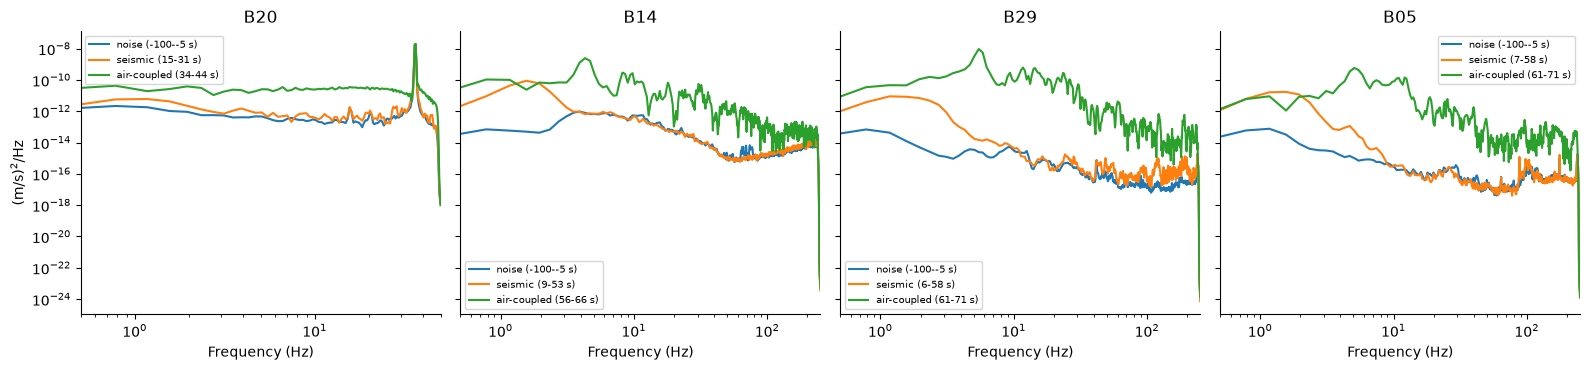

In [5]:
fig, axs = plt.subplots(1, len(STAS), figsize=(16, 3.8), sharey=True)
amp = []
for ax, sta in zip(axs, STAS):
    z = st.select(station=sta, channel='?HZ')[0].copy().filter('highpass', freq=0.5, corners=4, zerophase=True)
    fs = z.stats.sampling_rate
    ta, t_on = air.travel_time_s[sta], picks.first_arrival_s[sta]
    t_on = t_on if np.isfinite(t_on) else 15.0     # B20: from the burst
    wins = {'noise': (-100, -5), 'seismic': (t_on, ta - 3), 'air-coupled': (ta, ta + 10)}
    for lab, (a, b) in wins.items():
        x = z.slice(ORIGIN + a, ORIGIN + b).data
        f, p = welch(x - x.mean(), fs, nperseg=min(len(x), int(2.56 * fs)))
        ax.loglog(f[1:], p[1:], label=f'{lab} ({a:.0f}-{b:.0f} s)')
    ax.set(xlabel='Frequency (Hz)', xlim=(0.5, fs / 2), title=sta)
    s = z.copy().filter('bandpass', **BAND)
    amp.append(dict(station=sta, distance_km=stations.distance_km[sta],
                    seismic_peak_um_s=np.abs(s.slice(ORIGIN + t_on, ORIGIN + ta - 3).data).max() * 1e6,
                    aircoupled_peak_um_s=np.abs(s.slice(ORIGIN + ta, ORIGIN + ta + 10).data).max() * 1e6))
    ax.legend(fontsize=7)
axs[0].set_ylabel('(m/s)$^2$/Hz')
fig.tight_layout()
fig.savefig(OUT / 'seismic_spectra.png', dpi=150, bbox_inches='tight')
amp = pd.DataFrame(amp).set_index('station')
amp['aircoupled_over_seismic'] = amp.aircoupled_peak_um_s / amp.seismic_peak_um_s
amp.to_csv(OUT / 'seismic_amplitudes.csv')
display(amp.round(2))

## What this shows

* **Seismic first arrivals.** Seismic energy reaches every working Trillium long before the airwave. At
  19–21 km the first arrivals come 5.5–9 s after the origin (AIC picks in two bands; ±0.4–0.7 s between
  bands), giving apparent velocities of 2.1–3.8 km/s: B14 2.2, B29 3.5, B05 3.0 km/s. That is 47–55 s ahead
  of the airwave. These speeds are consistent with P energy refracted through the limestone beneath the
  surficial sediments; to be tested with a velocity model.
* **Wavetrain.** A long, emergent wavetrain follows and lasts until the airwave arrives. Its energy is
  mostly at 1–4 Hz, and its envelope peaks at 19–26 s (0.8–1.0 km/s). Narrow-band group velocities are
  0.6–1.0 km/s at 1–4 Hz, slower at 1–2 Hz than at 2–4 Hz. These look like surface or guided waves in the
  sediments; modelling is needed before calling them Rayleigh or Scholte waves.
* **B20 (11.8 km).** The noise is about ten times higher than at B29 and B05 (machinery tones and repeating
  transients). Only a burst at about 17–19 s (0.6–0.7 km/s, consistent with the wavetrain) stands out; the
  first arrival is buried.
* **Amplitudes.** Peak seismic vertical velocities are 5–18 µm/s, against 160–380 µm/s for the air-coupled
  motion: the airwave shakes the ground 11–56 times harder than the waves that travelled through it.
* **Why this is new.** At KSC the stations are usually within a few km of the source, so seismic and
  acoustic arrivals overlap, and launches are emergent. A single impulsive source 12–21 km away gives the
  first clean separation of the two.
* **Consistency check.** The seismic onsets come after the airwave-derived origin, as they must. With three
  stations at nearly the same distance they cannot constrain the origin on their own; B20, or the MSFC
  stations if their data turn up, would.